In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
import matplotlib.dates as mdates
import numpy as np

import sys
sys.path.append("/Users/alessandrostorer/Desktop/PhD/1st_yy/work/codes/BCO_observational/") # functions_collector
from functions_collector import great_circle, great_circle_haversine

import metpy

import pandas as pd
from IPython.display import display, HTML


## working local
local_path = {
              "joanne4": "/Users/alessandrostorer/Desktop/PhD/1st_yy/work/datasets/dropsondes_34/EUREC4A_JOANNE_Dropsonde-RD41_Level_4_v2.0.0.nc",
              "joanne3": "/Users/alessandrostorer/Desktop/PhD/1st_yy/work/datasets/dropsondes_34/EUREC4A_JOANNE_Dropsonde-RD41_Level_3_v2.0.0.nc",
              "beach4": "/Users/alessandrostorer/Desktop/PhD/1st_yy/work/datasets/dropsondes_34/ORCESTRA_BEACH_level_4.nc",
              "beach3":  "/Users/alessandrostorer/Desktop/PhD/1st_yy/work/datasets/dropsondes_34/ORCESTRA_BEACH_level_3.nc"
              }

In [2]:
import dropsonde_fit_library

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
joanne3_clean, joanne4 = dropsonde_fit_library.prepare_joanne34(local_path["joanne3"], local_path["joanne4"])

In [5]:
joanne3_clean

<xarray.Dataset> Size: 91MB
Dimensions:            (sonde_id: 782, altitude: 1001, nv: 2)
Coordinates:
  * sonde_id           (sonde_id) <U13 41kB 'HALO-0119_s04' ... 'HALO-0215_s51'
    launch_time        (sonde_id) datetime64[ns] 6kB 2020-01-19T17:33:12 ... ...
    circle             (sonde_id) int64 6kB 14 14 14 14 14 14 ... 84 84 84 84 84
    circle_lat_rep     (sonde_id) float32 3kB 13.27 13.27 13.27 ... 13.33 13.33
    circle_lon_rep     (sonde_id) float32 3kB -57.86 -57.86 ... -57.65 -57.65
  * altitude           (altitude) int16 2kB 0 10 20 30 ... 9970 9980 9990 10000
    interpolated_time  (sonde_id, altitude) datetime64[ns] 6MB ...
    lat                (sonde_id, altitude) float32 3MB nan 13.68 ... 13.45
    lon                (sonde_id, altitude) float32 3MB nan -58.62 ... -56.68
Dimensions without coordinates: nv
Data variables: (12/25)
    p                  (sonde_id, altitude) float32 3MB nan nan ... nan nan
    ta                 (sonde_id, altitude) float32 3MB nan nan ... nan nan
    rh                 (sonde_id, altitude) float32 3MB nan nan ... nan nan
    wspd               (sonde_id, altitude) float32 3MB nan 10.33 ... 30.2 30.18
    wdir               (sonde_id, altitude) float32 3MB nan 67.31 ... 240.9
    u                  (sonde_id, altitude) float32 3MB nan -9.531 ... 26.37
    ...                 ...
    m_ta               (sonde_id, altitude) float32 3MB nan 1.0 2.0 ... 2.0 1.0
    m_rh               (sonde_id, altitude) float32 3MB nan 1.0 2.0 ... 2.0 1.0
    m_gps              (sonde_id, altitude) float32 3MB nan 1.0 2.0 ... 2.0 1.0
    alt_bnds           (altitude, nv, sonde_id) float64 13MB -5.0 -5.0 ... 1e+04
    x                  (sonde_id, altitude) float64 6MB nan -82.3 ... 105.0
    y                  (sonde_id, altitude) float64 6MB nan 46.47 ... 14.25
Attributes: (12/16)
    title:                   EUREC4A JOANNE Level-3
    doi:                     10.25326/246
    created with:            run_joanne.py doi:10.5281/zenodo.5521192
    Conventions:             CF-1.8
    campaign_id:             EUREC4A
    project_id:              JOANNE
    ...                      ...
    JOANNE_version:          2.0.0
    author:                  Geet George
    author_email:            geet.george@mpimet.mpg.de
    featureType:             trajectory
    reference:               George et al., JOANNE : Joint dropsonde Observat...
    creation_time:           2021-09-22 14:35:24.817595 UTC

In [6]:
joanne4

<xarray.Dataset> Size: 9MB
Dimensions:          (circle: 71, altitude: 1001, sounding: 13)
Coordinates:
  * circle           (circle) int64 568B 14 15 16 17 18 19 ... 79 80 81 82 83 84
    circle_lon       (circle) float32 284B -57.86 -57.7 -57.71 ... -57.67 -57.65
    circle_lat       (circle) float32 284B 13.27 13.27 13.28 ... 13.33 13.33
    circle_time      (circle) datetime64[ns] 568B 2020-01-19T17:53:57.800000 ...
    segment_id       (circle) <U12 3kB 'HALO-0119_c1' ... 'HALO-0215_c6'
  * altitude         (altitude) int16 2kB 0 10 20 30 40 ... 9970 9980 9990 10000
  * sounding         (sounding) int64 104B 0 1 2 3 4 5 6 7 8 9 10 11 12
Data variables: (12/36)
    platform_id      (circle) object 568B 'HALO' 'HALO' 'HALO' ... 'HALO' 'HALO'
    flight_altitude  (circle) float32 284B 1.026e+04 1.029e+04 ... 1.119e+04
    circle_diameter  (circle) float32 284B 1.867e+05 2.225e+05 ... 2.236e+05
    u                (circle, altitude) float32 284kB nan -8.829 ... 25.54 25.55
    dudx             (circle, altitude) float32 284kB nan ... -6.027e-06
    dudy             (circle, altitude) float32 284kB nan ... -1.797e-05
    ...               ...
    se_dtadx         (circle, altitude) float32 284kB nan -0.0 ... -0.0 -0.0
    se_dtady         (circle, altitude) float32 284kB nan -0.0 ... -0.0 -0.0
    se_D             (circle, altitude) float32 284kB nan ... 8.735e-06
    se_vor           (circle, altitude) float32 284kB nan ... 9.522e-06
    se_W             (circle, altitude) float32 284kB 0.0 6.747e-06 ... 0.01219
    omega            (circle, altitude) float32 284kB nan 0.002026 ... nan nan
Attributes: (12/16)
    title:                   EUREC4A JOANNE Level-4
    doi:                     10.25326/246
    created with:            run_joanne.py doi:10.5281/zenodo.5521192
    Conventions:             CF-1.8
    campaign_id:             EUREC4A
    project_id:              JOANNE
    ...                      ...
    JOANNE_version:          2.0.0
    author:                  Geet George
    author_email:            geet.george@mpimet.mpg.de
    featureType:             trajectory
    reference:               George et al., JOANNE : Joint dropsonde Observat...
    creation_time:           2021-09-22 15:58:46.773760 UTC

In [ ]:
plt.scatter(joanne3_clean.lon, joanne3_clean.lat, facecolors='None', edgecolors="blue")
plt.scatter(joanne3_clean.circle_lon_rep, joanne3_clean.circle_lat_rep)
plt.scatter(joanne4.circle_lon, joanne4.circle_lat)

In [ ]:
def sign(x, y):
    '''
    the zonal and meridional distances from the centres of circles should be both positive and negative
    input : 
    x == lon or lat of sondes
    y == lon or lat of circles
    '''
    return xr.where(x >= y, 1.0, -1.0).where(x.notnull() & y.notnull())

x = sign(joanne3_clean.lon, joanne3_clean.circle_lon_rep)*great_circle_haversine(joanne3_clean.lon, joanne3_clean.lat, joanne3_clean.circle_lon_rep, joanne3_clean.lat)
y = sign(joanne3_clean.lat, joanne3_clean.circle_lat_rep)*great_circle_haversine(joanne3_clean.lon, joanne3_clean.lat, joanne3_clean.lon, joanne3_clean.circle_lat_rep)

x

In [ ]:
joanne3_clean["qv"] = (joanne3_clean.q * joanne3_clean.v)
qv_fit = joanne3_clean.groupby("circle").map(lambda g: dropsonde_fit_library.fit_circle_loc(g, "qv"))

In [ ]:
## compute vp qp
v_fit = joanne3_clean.groupby("circle").map(lambda g: dropsonde_fit_library.fit_circle_loc(g, "v"))

## mesoscale component
vb_dqb = v_fit.v_mean * joanne4.dqdy
vb_dqb_err = np.sqrt( ( v_fit.v_mean*joanne4.se_dqdy )**2 + ( v_fit.se_v_mean*joanne4.dqdy )**2  )

## v prime component
joanne3_clean["vp"] = joanne3_clean.v.groupby("circle") - v_fit.v_mean
joanne3_clean = dropsonde_fit_library.compute_circle_arcs(joanne3_clean)
grad_vp = joanne3_clean["qv"].groupby("circle").map(lambda g: dropsonde_fit_library.local_sonde_diff(g))

In [ ]:
joanne3_clean["vp_dqp_dy"] = joanne3_clean["vp"] * grad_vp["dvar_x"]
vp_dqp_dy_fit = joanne3_clean.groupby("circle").map(lambda g: dropsonde_fit_library.fit_circle_loc(g, "vp_dqp_dy"))

vp_dqp_dy_fit = vp_dqp_dy_fit.assign_coords(circle_lat=("circle", joanne4.circle_lat.values), circle_time=("circle", joanne4.circle_time.values))
vp_dqp_dy_fit = vp_dqp_dy_fit.assign_coords(circle_lon=("circle", joanne4.circle_lon.values))

vp_dqp_dy_fit

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
fig.suptitle("EUREC4A circles only")

low_layer = slice(0,1500)
gkg_perday = 1000*86400
perday     = 86400

y0 = gkg_perday * (-vb_dqb.sel(altitude=low_layer).sortby("circle_time"))

p1 = y0.plot(
    ax=ax[0], x="circle_time", y="altitude", vmin=-2.5, vmax=2.5, cmap="coolwarm",
)


y1 = perday * (-vp_dqp_dy_fit.vp_dqp_dy_mean.sel(altitude=low_layer).sortby("circle_time"))

p3 = y1.plot(
    ax=ax[1], x="circle_time", y="altitude", vmin=-2.5, vmax=2.5, cmap="coolwarm",
)


## relative errors on v' dq'
y2 = ((100*np.abs(vp_dqp_dy_fit.vp_dqp_dy_mean) / vp_dqp_dy_fit.se_vp_dqp_dy_mean).sel(altitude=low_layer).sortby("circle_time"))

p2 = y2.plot(
    ax=ax[2], x="circle_time", y="altitude", vmin=0, vmax=200, cmap="viridis",
)


for p in ( p1, p3, p2):
    p.colorbar.set_label(r"$\rm g~kg~day^{-1}$")

titles = [ r"$-\overline{v} \partial_y \overline{q}$", r"$-\overline{v'\partial_y q'}$", r"relative errors on $-\overline{v'\partial_y q'}$"]

for i, x in enumerate(ax.flatten()):
    x.set_title(titles[i])
    x.set_xlabel(r"lat / $\degree$")

    for spine in ["top", "right"]:
        x.spines[spine].set_visible(False)
    for spine in ["left", "bottom"]:
        x.spines[spine].set_position(("outward", 10))

### ORCESTRA case

In [7]:
b3, b4 = dropsonde_fit_library.prepare_beach34_NEW(75, 6)

In [8]:
b3

<xarray.Dataset> Size: 91MB
Dimensions:            (sonde_id: 912, altitude: 1460)
Coordinates:
  * sonde_id           (sonde_id) <U8 29kB 'ade4cdbe' 'c723db9f' ... 'ab47dc72'
    launch_altitude    (sonde_id) float32 4kB ...
    launch_lat         (sonde_id) float32 4kB ...
    launch_lon         (sonde_id) float32 4kB ...
    launch_time        (sonde_id) datetime64[ns] 7kB ...
    circle             (sonde_id) int64 7kB 0 0 0 0 0 0 0 ... 88 88 88 88 88 88
    circle_lon_rep     (sonde_id) float32 4kB -27.0 -27.0 ... -56.91 -56.91
    circle_lat_rep     (sonde_id) float32 4kB 5.0 5.0 5.0 ... 10.76 10.76 10.76
  * altitude           (altitude) float64 12kB 0.0 10.0 ... 1.458e+04 1.459e+04
Data variables: (12/24)
    flight_id          (sonde_id) <U14 51kB ...
    interpolated_time  (sonde_id, altitude) datetime64[ns] 11MB ...
    iwv                (sonde_id) float32 4kB ...
    lat                (sonde_id, altitude) float32 5MB nan 3.8 3.8 ... nan nan
    lon                (sonde_id, altitude) float32 5MB nan -27.17 ... nan nan
    p                  (sonde_id, altitude) float32 5MB ...
    ...                 ...
    v_qc               (sonde_id) int8 912B ...
    vaisala_serial_id  (sonde_id) <U9 33kB ...
    wdir               (sonde_id, altitude) float32 5MB ...
    wspd               (sonde_id, altitude) float32 5MB ...
    x                  (sonde_id, altitude) float64 11MB nan -18.52 ... nan nan
    y                  (sonde_id, altitude) float64 11MB nan -133.4 ... nan nan
Attributes: (12/16)
    title:             BEACH dropsonde dataset (Level 3)
    source:            dropsondes
    creator_name:      Helene Gloeckner, Theresa Mieslinger, Nina Robbins
    creator_email:     helene.gloeckner@mpimet.mpg.de, theresa.mieslinger@mpi...
    creator_id:        https://orcid.org/0009-0007-2741-9724, https://orcid.o...
    project:           ORCESTRA, PERCUSION, MAESTRO
    ...                ...
    license:           CC-BY-4.0
    featureType:       trajectoryProfile
    keywords:          ORCESTRA, BEACH, Sounding, Dropsondes, Tropics, Atmosp...
    summary:           This dataset is the Level 3 BEACH dataset. It contains...
    processing_level:  3
    history:           Level 1 ASPEN processing with Aspen V4.0.4 \nLevel 2 q...

In [9]:
b4

<xarray.Dataset> Size: 100MB
Dimensions:                   (circle: 77, altitude: 1460, sonde_id: 912)
Coordinates:
  * circle                    (circle) int64 616B 0 1 2 3 4 5 ... 84 85 86 87 88
    circle_lat                (circle) float32 308B 5.0 8.25 ... 12.17 10.76
    circle_lon                (circle) float32 308B -27.0 -26.39 ... -56.91
    circle_time               (circle) datetime64[ns] 616B ...
    sondes_per_circle         (circle) int64 616B 12 12 10 11 12 ... 13 13 12 13
  * altitude                  (altitude) float64 12kB 0.0 10.0 ... 1.459e+04
  * sonde_id                  (sonde_id) object 7kB 'ade4cdbe' ... 'ab47dc72'
    launch_time               (sonde_id) datetime64[ns] 7kB ...
    sonde_circle              (sonde_id) int64 7kB 0 0 0 0 0 ... 88 88 88 88 88
Data variables: (12/72)
    circle_altitude           (circle) float32 308B ...
    circle_id                 (circle) <U19 6kB ...
    circle_radius             (circle) float32 308B ...
    div                       (circle, altitude) float32 450kB ...
    div_sonde_relevance       (sonde_id, altitude) float32 5MB ...
    div_std_error             (circle, altitude) float32 450kB ...
    ...                        ...
    wspd_mean                 (circle, altitude) float32 450kB ...
    wvel                      (circle, altitude) float32 450kB ...
    wvel_sonde_relevance      (sonde_id, altitude) float32 5MB ...
    wvel_std_error            (circle, altitude) float32 450kB ...
    x                         (sonde_id, altitude) float32 5MB ...
    y                         (sonde_id, altitude) float32 5MB ...
Attributes: (12/16)
    title:             BEACH dropsonde dataset (Level 4)
    source:            dropsondes
    creator_name:      Helene Gloeckner, Theresa Mieslinger, Nina Robbins
    creator_email:     helene.gloeckner@mpimet.mpg.de, theresa.mieslinger@mpi...
    creator_id:        https://orcid.org/0009-0007-2741-9724, https://orcid.o...
    project:           ORCESTRA, PERCUSION, MAESTRO
    ...                ...
    license:           CC-BY-4.0
    featureType:       trajectoryProfile
    keywords:          ORCESTRA, BEACH, Sounding, Dropsondes, Tropics, Atmosp...
    summary:           This dataset is the Level 4 BEACH dataset. It contains...
    processing_level:  4
    history:           Level 1 ASPEN processing with Aspen V4.0.4 \nLevel 2 q...

In [ ]:
def sync_and_clean(b3, b4, min_sondes=6):
    # sondes present in both, keeping b3's order so both end up in the same order
    ids = b3.sonde_id.values[np.isin(b3.sonde_id.values, b4.sonde_id.values)]
    b3 = b3.sel(sonde_id=ids)
    b4 = b4.sel(sonde_id=ids)

    # circles with enough sondes left, counted from the labels in b3
    circ, cnt = np.unique(b3.circle.values, return_counts=True)
    ok = cnt >= min_sondes
    good, good_cnt = circ[ok], cnt[ok]

    # drop sondes of discarded circles from both, drop the circles from b4
    keep = np.isin(b3.circle.values, good)
    b3 = b3.isel(sonde_id=keep)
    b4 = b4.isel(sonde_id=keep).sel(circle=good)

    # update circle-level counts
    b4["sondes_per_circle"] = ("circle", good_cnt)
    return b3, b4


b3, b4 = sync_and_clean(b3, b4)

In [8]:
print("circle" in b4.coords, "circle" in b4.indexes)
print(b4.circle.values[:5], b4.circle.values[-3:])
print(np.unique(b3.circle.values)[-3:], b4.circle.values[-3:])

True True
[0 1 2 3 4] [86 87 88]
[86 87 88] [86 87 88]


In [9]:
b3["qv"] = (b3.q * b3.v)
qv_fit = b3.groupby("circle").map(lambda g: dropsonde_fit_library.fit_circle_loc(g, "qv"))

In [10]:
print("circle" in qv_fit.coords, "circle" in qv_fit.indexes)
print(qv_fit.circle.values[:5], qv_fit.circle.values[-3:])
print(np.unique(b3.circle.values)[-3:], qv_fit.circle.values[-3:])

True True
[0 1 2 3 4] [86 87 88]
[86 87 88] [86 87 88]


In [11]:
## compute vp qp
v_fit = b3.groupby("circle").map(lambda g: dropsonde_fit_library.fit_circle_loc(g, "v"))
q_fit = b3.groupby("circle").map(lambda g: dropsonde_fit_library.fit_circle_loc(g, "q"))
v_fit

<xarray.Dataset> Size: 5MB
Dimensions:    (circle: 77, altitude: 1460)
Coordinates:
  * circle     (circle) int64 616B 0 1 2 3 4 5 6 8 9 ... 81 82 83 84 85 86 87 88
  * altitude   (altitude) float64 12kB 0.0 10.0 20.0 ... 1.458e+04 1.459e+04
Data variables:
    v_mean     (circle, altitude) float64 899kB nan 7.081 7.22 ... nan nan nan
    d_v_dx     (circle, altitude) float64 899kB nan 0.004196 ... nan nan
    d_v_dy     (circle, altitude) float64 899kB nan 0.008831 ... nan nan
    se_dvdx    (circle, altitude) float64 899kB nan 0.00489 0.003923 ... nan nan
    se_dvdy    (circle, altitude) float64 899kB nan 0.004759 ... nan nan
    se_v_mean  (circle, altitude) float64 899kB nan 0.4536 0.3557 ... nan nan

In [12]:
## mesoscale component
vb_dqb = v_fit.v_mean * q_fit.d_q_dy
vb_dqb_err = np.sqrt( ( v_fit.v_mean*q_fit.se_dqdy )**2 + ( v_fit.se_v_mean*q_fit.d_q_dy )**2  )

In [13]:
## v prime component
b3["vp"] = b3.v.groupby("circle") - v_fit.v_mean
b3 = dropsonde_fit_library.compute_circle_arcs(b3)
grad_vp = b3["qv"].groupby("circle").map(lambda g: dropsonde_fit_library.local_sonde_diff(g))

DEBUG, Nan in theta: 223866 vs Nans in wrapped 224032


ValueError: Shape of array too small to calculate a numerical gradient, at least (edge_order + 1) elements are required.

In [ ]:
b3["vp_dqp_dy"] = b3["vp"] * grad_vp["dvar_x"]
vp_dqp_dy_fit = b3.groupby("circle").map(lambda g: dropsonde_fit_library.fit_circle_loc(g, "vp_dqp_dy"))

# vp_dqp_dy_fit = vp_dqp_dy_fit.assign_coords(circle_lat=("circle", b4.circle_lat.values), circle_time=("circle", b4.circle_time.values))
# vp_dqp_dy_fit = vp_dqp_dy_fit.assign_coords(circle_lon=("circle", b4.circle_lon.values))

vp_dqp_dy_fit

<xarray.Dataset> Size: 6MB
Dimensions:            (circle: 87, altitude: 1460)
Coordinates:
  * circle             (circle) int64 696B 0 1 2 3 4 5 6 ... 83 84 85 86 87 88
    circle_lat         (circle) float32 348B 5.0 8.25 11.5 ... 11.54 12.17 10.76
    circle_time        (circle) datetime64[ns] 696B 2024-08-11T14:45:42.50000...
    circle_lon         (circle) float32 348B -27.0 -26.39 ... -54.91 -56.91
  * altitude           (altitude) float64 12kB 0.0 10.0 ... 1.458e+04 1.459e+04
Data variables:
    vp_dqp_dy_mean     (circle, altitude) float64 1MB nan -4.518e-05 ... nan nan
    d_vp_dqp_dy_dx     (circle, altitude) float64 1MB nan -4.84e-07 ... nan nan
    d_vp_dqp_dy_dy     (circle, altitude) float64 1MB nan 1.399e-06 ... nan nan
    se_dvp_dqp_dydx    (circle, altitude) float64 1MB nan 8.427e-07 ... nan nan
    se_dvp_dqp_dydy    (circle, altitude) float64 1MB nan 8.203e-07 ... nan nan
    se_vp_dqp_dy_mean  (circle, altitude) float64 1MB nan 7.818e-05 ... nan nan

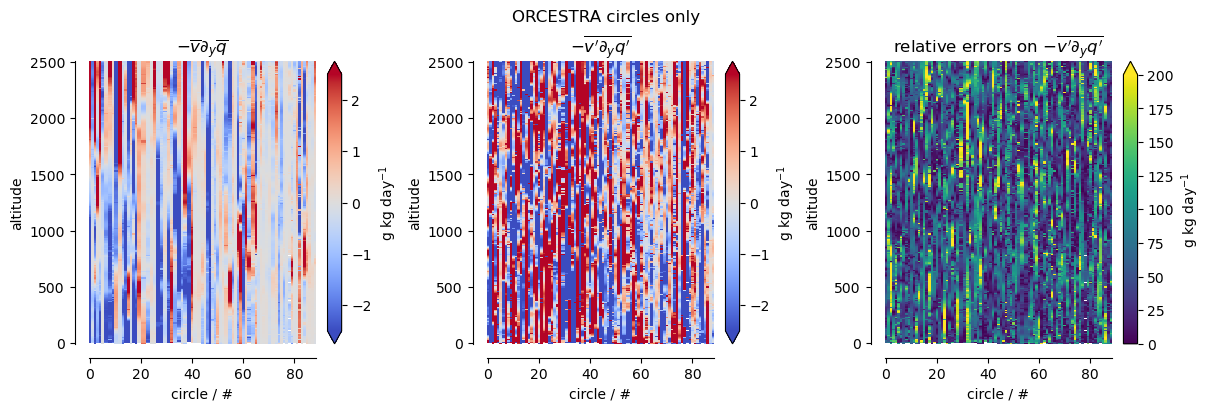

In [115]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
fig.suptitle("ORCESTRA circles only")

low_layer = slice(0,2500)
gkg_perday = 1000*86400
perday     = 86400

y0 = perday * (-vb_dqb.sel(altitude=low_layer).sortby("circle"))

p1 = y0.plot(
    ax=ax[0], x="circle", y="altitude", vmin=-2.5, vmax=2.5, cmap="coolwarm",
)


y1 = perday * (-vp_dqp_dy_fit.vp_dqp_dy_mean.sel(altitude=low_layer).sortby("circle"))

p3 = y1.plot(
    ax=ax[1], x="circle", y="altitude", vmin=-2.5, vmax=2.5, cmap="coolwarm",
)


## relative errors on v' dq'
y2 = ((100*np.abs(vp_dqp_dy_fit.vp_dqp_dy_mean) / vp_dqp_dy_fit.se_vp_dqp_dy_mean).sel(altitude=low_layer).sortby("circle"))

p2 = y2.plot(
    ax=ax[2], x="circle", y="altitude", vmin=0, vmax=200, cmap="viridis",
)


for p in ( p1, p3, p2):
    p.colorbar.set_label(r"$\rm g~kg~day^{-1}$")

titles = [ r"$-\overline{v} \partial_y \overline{q}$", r"$-\overline{v'\partial_y q'}$", r"relative errors on $-\overline{v'\partial_y q'}$"]

for i, x in enumerate(ax.flatten()):
    x.set_title(titles[i])
    x.set_xlabel(r"circle / #")

    for spine in ["top", "right"]:
        x.spines[spine].set_visible(False)
    for spine in ["left", "bottom"]:
        x.spines[spine].set_position(("outward", 10))